# 3 — Validation automatique par QA

La baseline conserve le validateur QA local étudié (TF-IDF et recouvrement lexical). La méthode avancée ajoute Gemini 3.5 Flash-Lite, un modèle multilingue utilisé en français pour répondre à la question à partir des passages du cours, identifier les options étayées et fournir une citation. L’acceptation exige une réponse unique, correcte par rapport à la référence et accompagnée d’une preuve retrouvée dans le contexte.

La comparaison porte sur les mêmes QCM avec absence de filtre, QA local et QA Gemini. TF-IDF reste la méthode de référence étudiée. L’appel Gemini transmet les questions, options et extraits de cours à Google ; les interactions sont sans état (`store=False`). La clé n’est jamais enregistrée dans le notebook : renseigner `GEMINI_API_KEY` dans le fichier local `.env` à la racine du projet avant l’exécution.

In [1]:
from pathlib import Path
import sys, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'requirements.txt').exists(): ROOT = ROOT.parent
if not (ROOT / 'requirements.txt').exists(): raise FileNotFoundError('Racine du projet introuvable.')
sys.path.insert(0, str(ROOT))
from src.qcm_pipeline import load_qa_model, validate_mcqs_with_qa, make_filter_challenges
PASSAGES_PATH = ROOT / 'data' / 'processed' / 'passages.csv'
CANDIDATES_PATH = ROOT / 'data' / 'processed' / 'qcm_candidats.csv'
if not PASSAGES_PATH.exists() or not CANDIDATES_PATH.exists():
    raise FileNotFoundError('Exécuter les notebooks 01 et 02 avant la validation.')
passages = pd.read_csv(PASSAGES_PATH)
candidates = pd.read_csv(CANDIDATES_PATH)
QA_BACKEND = 'local'  # Choisir 'camembert' seulement si le dépôt du modèle est accessible.
print(f'Chargement du validateur QA ({QA_BACKEND}).')
qa_model = load_qa_model(backend=QA_BACKEND)
print('Validateur chargé.')

Chargement du validateur QA (local).
Validateur chargé.


In [2]:
validated = validate_mcqs_with_qa(candidates, passages, qa_model)
OUT = ROOT / 'data' / 'processed'
OUT.mkdir(parents=True, exist_ok=True)
validated.to_csv(OUT / 'qcm_valides_et_rejetes.csv', index=False, encoding='utf-8-sig')
accepted = validated.loc[validated['accepted']].copy()
accepted.to_csv(OUT / 'qcm_acceptes.csv', index=False, encoding='utf-8-sig')
rejection_rate = 1 - len(accepted) / len(validated) if len(validated) else float('nan')
comparison = pd.DataFrame([
    {'configuration': 'Baseline — sans filtre QA', 'nombre': len(candidates), 'taux_rejet': 0.0},
    {'configuration': 'Avancé — QA extractif local', 'nombre': len(accepted), 'taux_rejet': rejection_rate},
])
comparison.to_csv(ROOT / 'results' / 'comparaison_filtrage.csv', index=False, encoding='utf-8-sig')
display(comparison)
print('Exemples acceptés :')
display(accepted[['question_id', 'question', 'qa_evidence', 'qa_model_confidence', 'qa_margin']].head(5))
print('Motifs de rejet :')
display(validated.loc[~validated['accepted'], 'rejection_reason'].value_counts().rename_axis('motif').to_frame('nombre'))

,configuration,nombre,taux_rejet
0,Baseline — sans filtre QA,120,0.000000
1,Avancé — QA extractif local,113,0.058333


Exemples acceptés :


,question_id,question,qa_evidence,qa_model_confidence,qa_margin
0,Q0001,"Selon le support, quelle affirmation concernan...",L’œil humain ne perçoit pas la couleur comme u...,0.410228,0.857143
1,Q0002,"Selon le support, quelle affirmation concernan...",1.Le cerveau devine d’abord la couleur de la s...,0.337119,0.857143
3,Q0004,"Selon le support, quelle affirmation concernan...",La machine ne possède pas cette capacité d’ada...,0.442947,0.846154
4,Q0005,"Selon le support, quelle affirmation concernan...",Différence fondamentale entre vision humaine e...,0.473691,0.857143
5,Q0006,"Selon le support, quelle affirmation concernan...",Chaque élément de l'image est appelé « pixel »...,0.416866,0.857143


Motifs de rejet :


,nombre
motif,
option_QA_differente_de_la_reponse_reference,5
options_non_uniques_selon_le_modele_QA,2


## Validation QA avec Gemini

Cette étape utilise l’API Gemini sur les mêmes candidats que le validateur local. Elle nécessite une clé créée par l’utilisateur et placée dans le fichier local `.env` (copié depuis `.env.example`). Le modèle par défaut est `gemini-3.5-flash-lite` ; `GEMINI_MODEL` permet de choisir un autre modèle autorisé par le compte. Les appels sont regroupés par lots pour limiter le nombre de requêtes.

In [3]:
import os
from src.gemini_qa import create_gemini_client, validate_mcqs_with_gemini

GEMINI_MODEL = os.environ.get('GEMINI_MODEL', 'gemini-3.5-flash-lite')
with create_gemini_client() as gemini_client:
    gemini_validated = validate_mcqs_with_gemini(
        candidates, passages, gemini_client, batch_size=10
    )

gemini_validated.to_csv(OUT / 'qcm_valides_et_rejetes_gemini.csv', index=False, encoding='utf-8-sig')
gemini_accepted = gemini_validated.loc[gemini_validated['accepted']].copy()
gemini_accepted.to_csv(OUT / 'qcm_acceptes_gemini.csv', index=False, encoding='utf-8-sig')
gemini_rejection_rate = 1 - len(gemini_accepted) / len(gemini_validated)
comparison = pd.concat([
    comparison,
    pd.DataFrame([{
        'configuration': f'QA Gemini ({GEMINI_MODEL})',
        'nombre': len(gemini_accepted),
        'taux_rejet': gemini_rejection_rate,
    }]),
], ignore_index=True)
comparison.to_csv(ROOT / 'results' / 'comparaison_filtrage.csv', index=False, encoding='utf-8-sig')
print(f'Validation Gemini terminée : {len(gemini_accepted)} QCM retenus sur {len(gemini_validated)}.')
display(comparison)
display(gemini_validated[['question_id', 'qa_predicted_answer', 'qa_evidence_supported', 'qa_unique', 'qa_correct', 'accepted']].head(5))

Validation Gemini terminée : 103 QCM retenus sur 120.


,configuration,nombre,taux_rejet
0,Baseline — sans filtre QA,120,0.000000
1,Avancé — QA extractif local,113,0.058333
2,QA Gemini (gemini-3.5-flash-lite),103,0.141667


,question_id,qa_predicted_answer,qa_evidence_supported,qa_unique,qa_correct,accepted
0,Q0001,L’œil humain ne perçoit pas la couleur comme u...,True,True,True,True
1,Q0002,Chaque cerveau estime la lumière différemment ...,True,True,False,False
2,Q0003,Chaque cerveau estime la lumière différemment ...,True,True,True,True
3,Q0004,La machine ne possède pas cette capacité d’ada...,True,True,True,True
4,Q0005,Différence fondamentale entre vision humaine e...,True,True,True,True


## Ablation : mesure de l’effet du filtre

On compare le générateur sans filtre (baseline) au générateur suivi du QA extractif local. Une petite série de contrôles est aussi construite : doublon de bonne réponse (ambiguïté) et question sur une notion absente. Ces contrôles servent à vérifier le comportement du filtre ; ils ne sont pas assimilés à une annotation humaine.

,challenge_type,nombre,acceptes,taux_rejet
0,ambiguite_introduite,12,0,1.0
1,question_sans_reponse,12,0,1.0


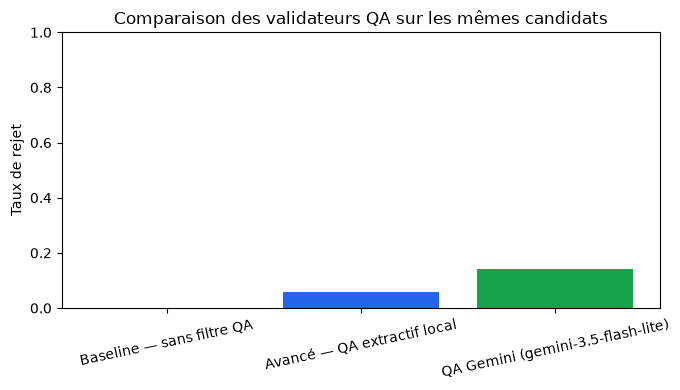

In [4]:
challenges = make_filter_challenges(candidates, count=min(12, len(candidates)))
challenged = validate_mcqs_with_qa(challenges, passages, qa_model)
challenged.to_csv(OUT / 'controles_ablation.csv', index=False, encoding='utf-8-sig')
challenge_summary = (challenged.groupby('challenge_type', as_index=False)
                     .agg(nombre=('question_id', 'size'), acceptes=('accepted', 'sum')))
challenge_summary['taux_rejet'] = 1 - challenge_summary['acceptes'] / challenge_summary['nombre']
challenge_summary.to_csv(ROOT / 'results' / 'resultats_controles_ablation.csv', index=False, encoding='utf-8-sig')
display(challenge_summary)
fig, ax = plt.subplots(figsize=(7, 4))
colors = ['#64748b', '#2563eb', '#16a34a'][:len(comparison)]
ax.bar(comparison['configuration'], comparison['taux_rejet'], color=colors)
ax.set_ylabel('Taux de rejet')
ax.set_ylim(0, 1)
ax.set_title('Comparaison des validateurs QA sur les mêmes candidats')
ax.tick_params(axis='x', rotation=12)
plt.tight_layout()
plt.show()